In [1]:
import numpy as np
from numpy.typing import NDArray
from typing import Any
import matplotlib.pyplot as plt
#plt.style.use('seaborn-whitegrid')

In [2]:
def get_data_path(
    source: str,
    target: str,
    id: int,
    abbrev: bool = False,
    prefix: str = "",
    model_name: str = "",
    foldername: str = "TTA1",
):
    folder_path = (
        f"/g/kreshuk/talks/domain_gap/experiments/patch_classification/"
        + f"{source}_to_{target}/consistency/predictions/{model_name}/{foldername}/"
    )

    if abbrev == True:
        data_path = (
            folder_path
            + f"{source[0].upper()}to{target[0].upper()}{prefix}_aug{id}.npz"
        )

    else:
        data_path = folder_path + f"RN18_{source}80_full2_{target}_Aug_{id}.npz"

    return data_path

In [3]:
def get_soft_predictions(
    source: str,
    target: str,
    num_runs: int = 9,
    start_id: int = 0,
    abbrev: bool = True,
    prefix: str = "",
    model_name: str = "",
    foldername: str = "TTA1",
) -> tuple[NDArray[Any], NDArray[Any], NDArray[Any], NDArray[Any]]:
    predictions = []
    soft_predictions = []
    gt_labels = []
    f1_scores = np.zeros(num_runs)

    for i in range(num_runs):
        data_path = get_data_path(
            source, target, start_id + i, abbrev, prefix, model_name, foldername
        )
        with np.load(data_path, "r") as f:
            predictions.append(f["predictions"])
            soft_predictions.append(f["soft_predictions"])
            gt_labels.append(f["labels"])
            f1_scores[i] = f["f1_score"]

    return (
        np.vstack(predictions),
        np.vstack(soft_predictions),
        np.vstack(gt_labels),
        f1_scores,
    )

In [4]:
HtoE_2_preds, HtoE_2_soft_preds, HtoE_2_gts, HtoE_2_f1s = get_soft_predictions(source ='Hmito', target='epfl', prefix="_2soft", model_name="RN18_Hmito80_aug2_soft")
HtoH_2_preds, HtoH_2_soft_preds, HtoH_2_gts, HtoH_2_f1s = get_soft_predictions(source ='Hmito', target='Hmito', prefix="_2soft", model_name="RN18_Hmito80_aug2_soft")
HtoR_2_preds, HtoR_2_soft_preds, HtoR_2_gts, HtoR_2_f1s = get_soft_predictions(source ='Hmito', target='Rmito', prefix="_2soft", model_name="RN18_Hmito80_aug2_soft")
HtoV_2_preds, HtoV_2_soft_preds, HtoV_2_gts, HtoV_2_f1s = get_soft_predictions(source ='Hmito', target='VNC', prefix="_2soft", model_name="RN18_Hmito80_aug2_soft")

In [5]:
EtoE_5_preds, EtoE_5_soft_preds, EtoE_5_gts, EtoE_5_f1s = get_soft_predictions("epfl", "epfl", num_runs=9, start_id=0, abbrev=True, prefix="_5soft", model_name="RN18_epfl80_aug5_soft")
EtoH_5_preds, EtoH_5_soft_preds, EtoH_5_gts, EtoH_5_f1s = get_soft_predictions("epfl", "Hmito", num_runs=9, start_id=0, abbrev=True, prefix="_5soft", model_name="RN18_epfl80_aug5_soft")
EtoR_5_preds, EtoR_5_soft_preds, EtoR_5_gts, EtoR_5_f1s = get_soft_predictions("epfl", "Rmito", num_runs=9, start_id=0, abbrev=True, prefix="_5soft", model_name="RN18_epfl80_aug5_soft")
EtoV_5_preds, EtoV_5_soft_preds, EtoV_5_gts, EtoV_5_f1s = get_soft_predictions("epfl", "VNC", num_runs=9, start_id=0, abbrev=True, prefix="_5soft", model_name="RN18_epfl80_aug5_soft")


In [6]:
RtoE_3_preds, RtoE_3_soft_preds, RtoE_3_gts, RtoE_3_f1s = get_soft_predictions("Rmito", "epfl", num_runs=9, start_id=0, abbrev=True, prefix="_3soft", model_name="RN18_Rmito80_aug3_soft")
RtoH_3_preds, RtoH_3_soft_preds, RtoH_3_gts, RtoH_3_f1s = get_soft_predictions("Rmito", "Hmito", num_runs=9, start_id=0, abbrev=True, prefix="_3soft", model_name="RN18_Rmito80_aug3_soft")
RtoR_3_preds, RtoR_3_soft_preds, RtoR_3_gts, RtoR_3_f1s = get_soft_predictions("Rmito", "Rmito", num_runs=9, start_id=0, abbrev=True, prefix="_3soft", model_name="RN18_Rmito80_aug3_soft")
RtoV_3_preds, RtoV_3_soft_preds, RtoV_3_gts, RtoV_3_f1s = get_soft_predictions("Rmito", "VNC", num_runs=9, start_id=0, abbrev=True, prefix="_3soft", model_name="RN18_Rmito80_aug3_soft")

In [12]:
def plot_combined_transfer_hists(
    transfer_values:list, 
    transfers:list, 
    value_label: str, 
    nbins:int=50,
    figsize=(10,10),
    ylim=1,
    fontsize=20,
    save_path: str = None
):  
    for i, transfer in enumerate(transfers):
        plt.figure(figsize=figsize)
    
        data = transfer_values[i]
        _ = plt.hist(data, weights=np.ones(len(data)) / len(data), bins=nbins)
        _ = plt.title(f"{transfer} prediction ratio", fontsize=fontsize+5)
        _ = plt.xticks(fontsize=fontsize)
        _ = plt.yticks(fontsize=fontsize)
        _ = plt.xlabel('P(x=1)', fontsize=fontsize)
        _ = plt.ylabel('Frequency', fontsize=fontsize)
        _ = plt.ylim(0,ylim)
        _ = plt.grid()
        if save_path is not None:
            plt.savefig(f"{save_path}/prediction_ratio_{transfer}", pad_inches=0, format='svg')
        plt.show()

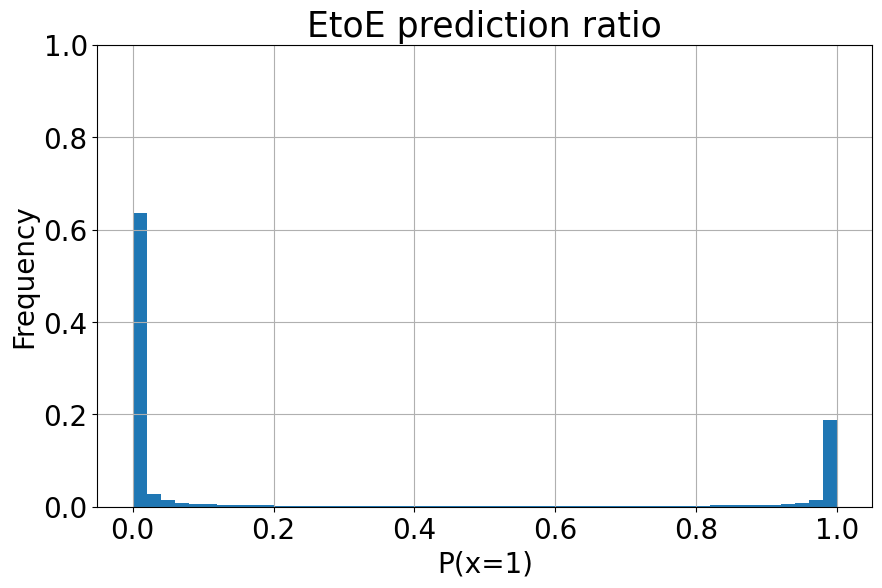

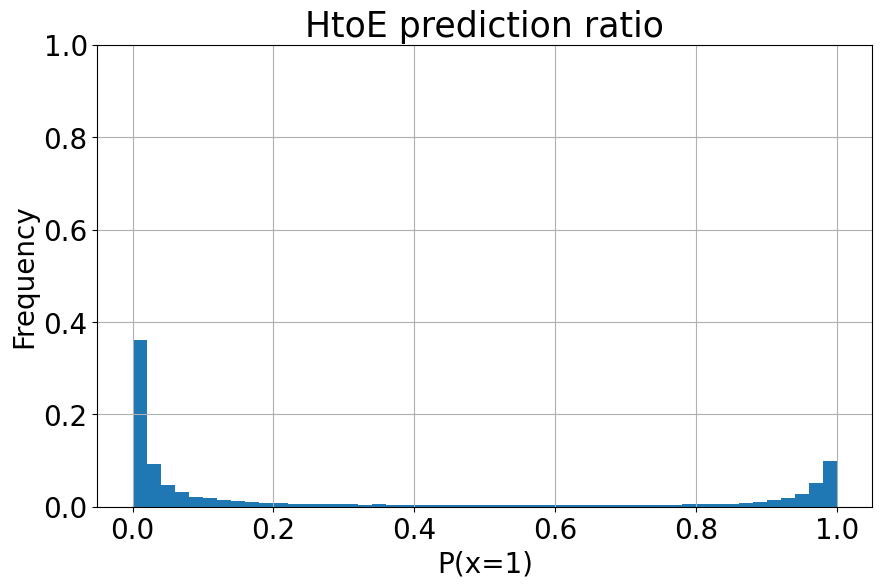

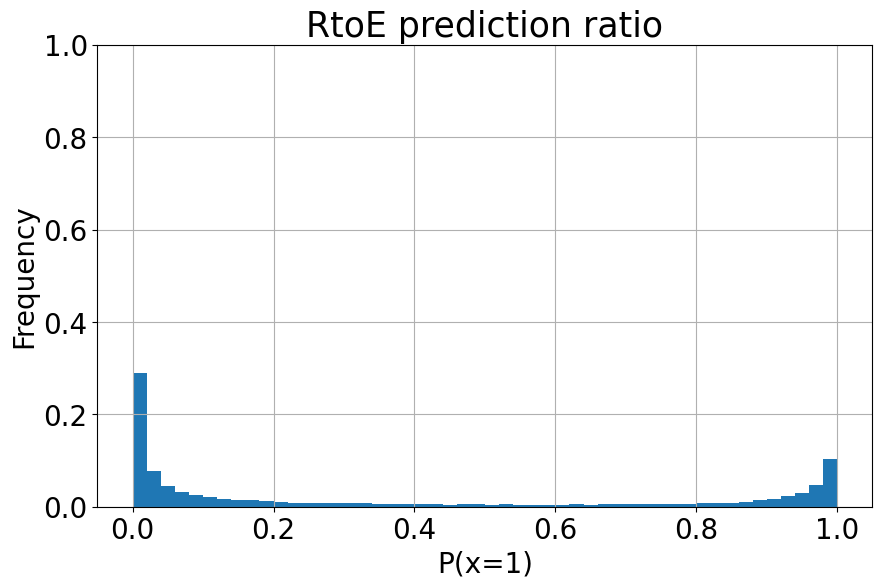

In [8]:
plot_combined_transfer_hists([np.concatenate(EtoE_5_soft_preds), np.concatenate(HtoE_2_soft_preds), np.concatenate(RtoE_3_soft_preds)], ['EtoE', 'HtoE', 'RtoE'], "predictions", figsize=(10,6))

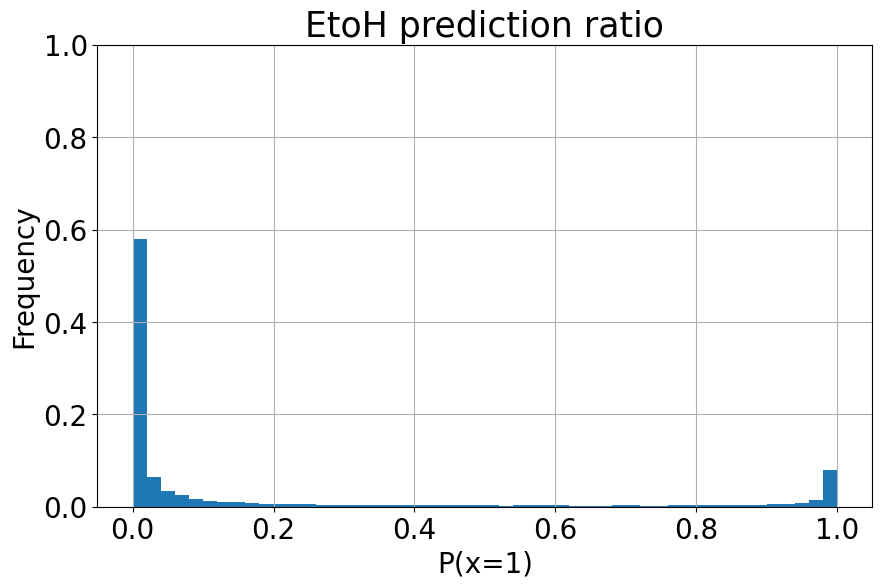

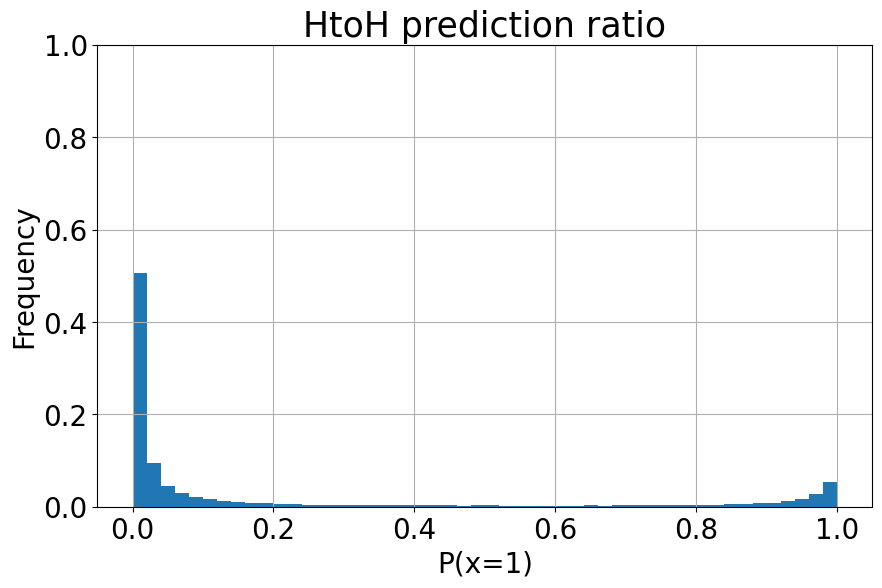

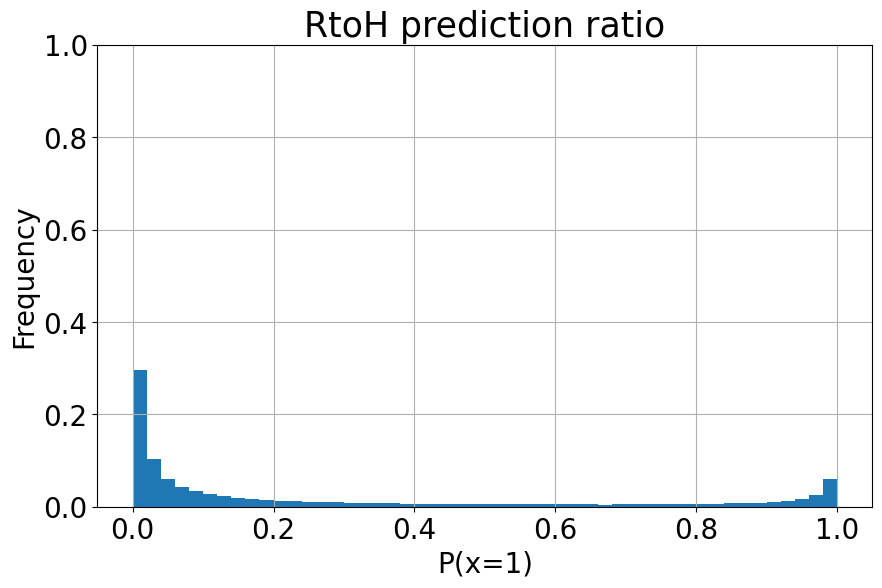

In [9]:
plot_combined_transfer_hists([np.concatenate(EtoH_5_soft_preds), np.concatenate(HtoH_2_soft_preds), np.concatenate(RtoH_3_soft_preds)], ['EtoH', 'HtoH', 'RtoH'], "predictions", figsize=(10,6))

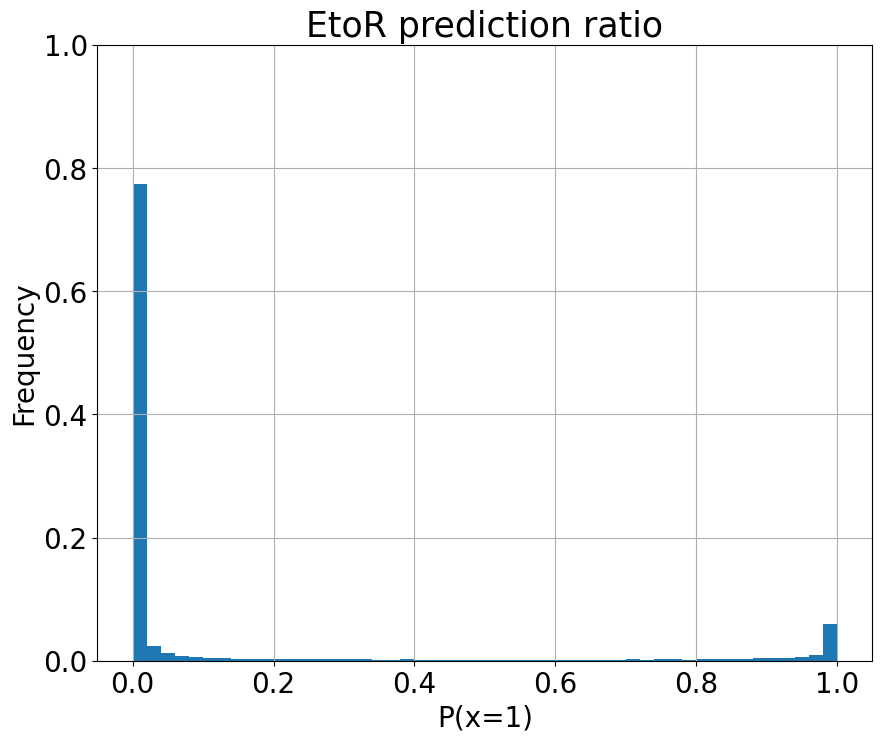

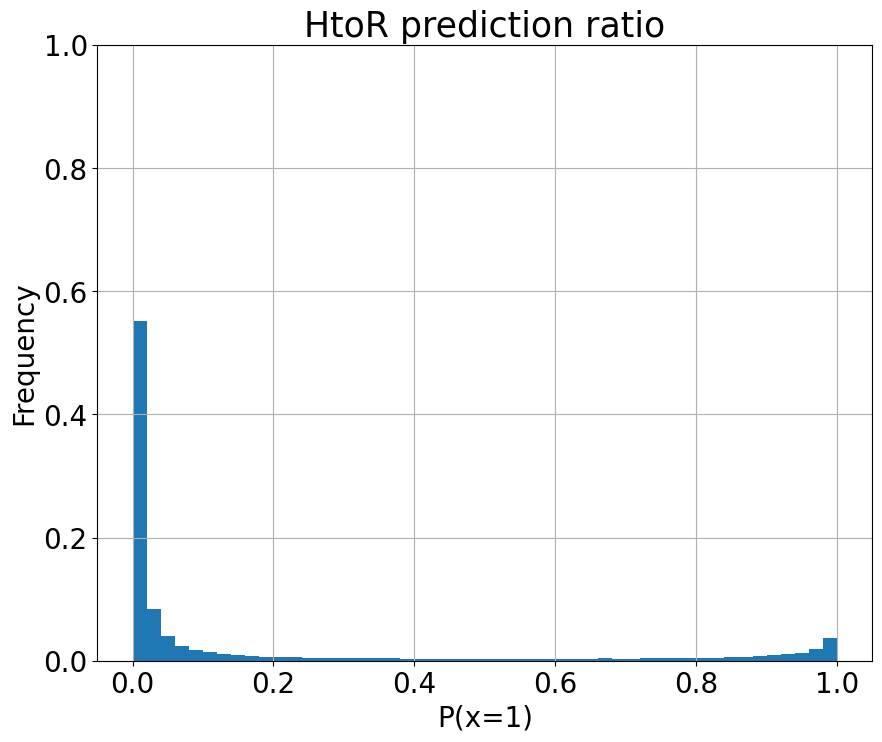

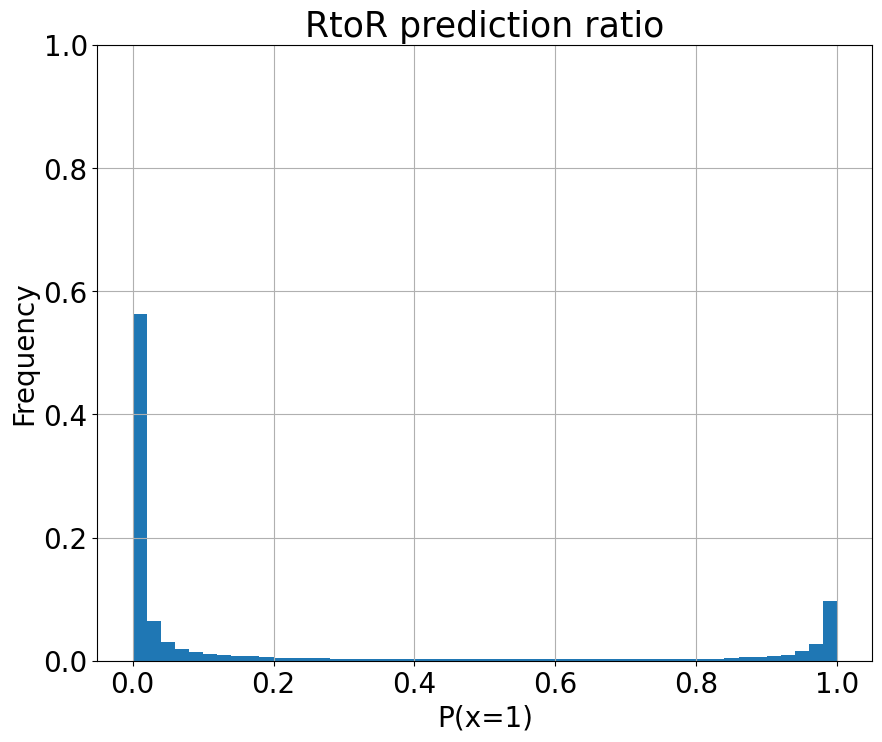

In [14]:
plot_combined_transfer_hists(
    [np.concatenate(EtoR_5_soft_preds), np.concatenate(HtoR_2_soft_preds), np.concatenate(RtoR_3_soft_preds)], 
    ['EtoR', 'HtoR', 'RtoR'], 
    "predictions", 
    figsize=(10,8),
    save_path="/g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/figures/prediction_ratio"
)